# Customer Churn Prediction & SQL Analytics

**Question:** Which customers are more likely to leave a telecom provider? This notebook uses the [IBM Telco Customer Churn sample](https://github.com/IBM/telco-customer-churn-on-icp4d/blob/master/data/Telco-Customer-Churn.csv). Run all cells from the `customer-churn` directory. The label `Churn` means the customer left; these are historical associations, not causal effects.

Workflow: inspect → describe and visualize → split → preprocess inside pipelines → fit two classifiers → compare held-out results → query the same customers in SQLite. We use the test set once for evaluation and do no tuning on it.


In [1]:
from pathlib import Path
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

DATA_PATH = Path('data/Telco-Customer-Churn.csv')
assert DATA_PATH.exists(), f'Missing {DATA_PATH}; follow README.md to download it.'
raw = pd.read_csv(DATA_PATH)
display(raw.head())


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Inspect the real data

`TotalCharges` arrives as text because 11 rows contain a blank string. We convert those blanks to missing numeric values before analysis. The original CSV stays unchanged. `customerID` is an identifier, not a predictive feature.


In [2]:
print('Shape:', raw.shape)
display(raw.dtypes.rename('dtype').to_frame())
print('Exact duplicate rows:', raw.duplicated().sum())
print('Duplicate customer IDs:', raw['customerID'].duplicated().sum())
print('Raw missing cells:', int(raw.isna().sum().sum()))
print('Blank TotalCharges:', int(raw['TotalCharges'].astype(str).str.strip().eq('').sum()))

df = raw.copy()
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
assert set(df['Churn']) == {'No', 'Yes'}
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1}).astype(int)
display(df.isna().sum().loc[lambda x: x > 0].rename('missing_after_conversion').to_frame())
print('Overall churn rate:', f"{df['Churn'].mean():.2%}")


Shape: (7043, 21)


,dtype
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


Exact duplicate rows: 0
Duplicate customer IDs: 0
Raw missing cells: 0
Blank TotalCharges: 11


,missing_after_conversion
TotalCharges,11


Overall churn rate: 26.54%


## 2. Descriptive statistics and three charts

The mean is sensitive to extreme bills; the median is the middle bill; standard deviation measures spread. A conditional churn rate is `P(Churn = 1 | group)` and is an association, not evidence that the group causes churn. These summaries use the full dataset for description only. The modeling choices below are fixed in advance.


In [3]:
display(df[['tenure', 'MonthlyCharges', 'TotalCharges']].agg(['mean', 'median', 'std']).round(2))
contract_summary = df.groupby('Contract', as_index=False).agg(
    customers=('Churn', 'size'), churned=('Churn', 'sum'),
    churn_rate=('Churn', 'mean'), mean_monthly_charges=('MonthlyCharges', 'mean'))
display(contract_summary.round(3))
charge_edges = [0, 50, 80, np.inf]
charge_labels = ['Under $50', '$50 to <$80', '$80 or more']
df['charge_band'] = pd.cut(df['MonthlyCharges'], bins=charge_edges,
                           labels=charge_labels, right=False)
display(df.groupby('charge_band', observed=True)['Churn']
        .agg(customers='size', churn_rate='mean').round(3))


,tenure,MonthlyCharges,TotalCharges
mean,32.37,64.76,2283.30
median,29.00,70.35,1397.48
std,24.56,30.09,2266.77


,Contract,customers,churned,churn_rate,mean_monthly_charges
0,Month-to-month,3875,1655,0.427,66.398
1,One year,1473,166,0.113,65.049
2,Two year,1695,48,0.028,60.770


,customers,churn_rate
charge_band,,
Under $50,2294,0.157
$50 to <$80,2072,0.289
$80 or more,2677,0.340


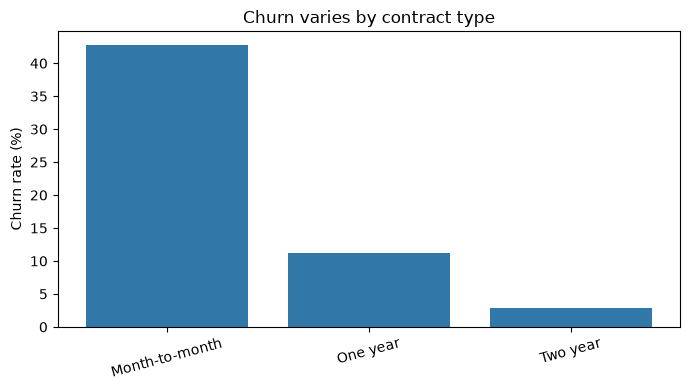

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(contract_summary['Contract'], 100 * contract_summary['churn_rate'], color='#3178a8')
ax.set(ylabel='Churn rate (%)', title='Churn varies by contract type')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


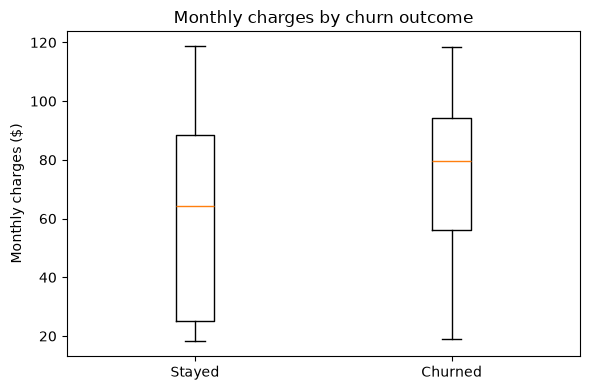

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot([df.loc[df.Churn == 0, 'MonthlyCharges'],
            df.loc[df.Churn == 1, 'MonthlyCharges']], tick_labels=['Stayed', 'Churned'])
ax.set(ylabel='Monthly charges ($)', title='Monthly charges by churn outcome')
plt.tight_layout()
plt.show()


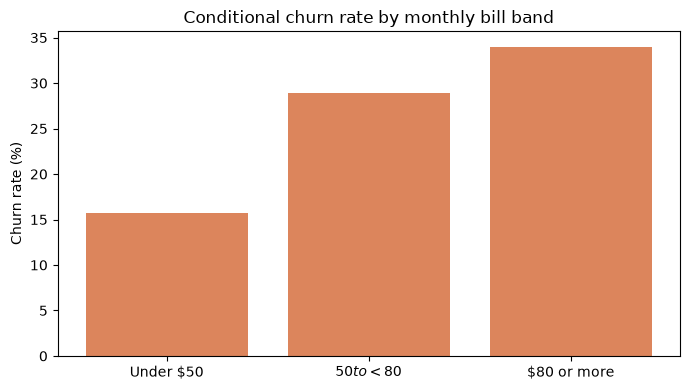

In [6]:
band_summary = df.groupby('charge_band', observed=True)['Churn'].mean()
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(band_summary.index.astype(str), 100 * band_summary.values, color='#dc855c')
ax.set(ylabel='Churn rate (%)', title='Conditional churn rate by monthly bill band')
plt.tight_layout()
plt.show()


## 3. Split and preprocess without leakage

An 80/20 stratified split preserves the class ratio. Median imputation and scaling for numeric columns, and most-frequent imputation plus one-hot encoding for categorical columns, are **fitted only on training data** by each pipeline. `SeniorCitizen` is a 0/1 numeric indicator. The descriptive `charge_band`, `customerID`, and label are excluded from features.


In [7]:
X = df.drop(columns=['customerID', 'Churn', 'charge_band'])
y = df['Churn']
numeric_features = ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
categorical_features = [col for col in X if col not in numeric_features]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

def make_preprocessor():
    numeric = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ])
    categorical = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore')),
    ])
    return ColumnTransformer([
        ('numeric', numeric, numeric_features),
        ('categorical', categorical, categorical_features),
    ])

print('Train/test:', X_train.shape, X_test.shape)
print('Churn rates:', f'train={y_train.mean():.3f}', f'test={y_test.mean():.3f}')
assert set(X_train.index).isdisjoint(X_test.index)
assert 'customerID' not in X_train and 'charge_band' not in X_train


Train/test: (5634, 19) (1409, 19)
Churn rates: train=0.265 test=0.265


## 4. Fit only two models

Logistic regression gives a linear score followed by a sigmoid probability. A random forest averages many decision trees. Both use the same split and preprocessing steps. We use the default decision threshold of 0.5 and do not tune hyperparameters against the test set.


In [8]:
models = {
    'Logistic Regression': Pipeline([
        ('preprocess', make_preprocessor()),
        ('model', LogisticRegression(max_iter=1000, random_state=42)),
    ]),
    'Random Forest': Pipeline([
        ('preprocess', make_preprocessor()),
        ('model', RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)),
    ]),
}
results = []
matrices = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predicted = model.predict(X_test)
    probability = model.predict_proba(X_test)[:, 1]
    matrices[name] = confusion_matrix(y_test, predicted, labels=[0, 1])
    results.append({
        'model': name,
        'accuracy': accuracy_score(y_test, predicted),
        'precision': precision_score(y_test, predicted),
        'recall': recall_score(y_test, predicted),
        'f1': f1_score(y_test, predicted),
        'roc_auc': roc_auc_score(y_test, probability),
        'TN': matrices[name][0, 0], 'FP': matrices[name][0, 1],
        'FN': matrices[name][1, 0], 'TP': matrices[name][1, 1],
    })
comparison = pd.DataFrame(results).set_index('model')
display(comparison.round(3))
for name, matrix in matrices.items():
    print(name, 'confusion matrix [[TN, FP], [FN, TP]]:')
    display(pd.DataFrame(matrix, index=['Actual stayed', 'Actual churned'],
                         columns=['Predicted stayed', 'Predicted churned']))


,accuracy,precision,recall,f1,roc_auc,TN,FP,FN,TP
model,,,,,,,,,
Logistic Regression,0.806,0.657,0.559,0.604,0.842,926,109,165,209
Random Forest,0.776,0.600,0.465,0.524,0.819,919,116,200,174


Logistic Regression confusion matrix [[TN, FP], [FN, TP]]:


,Predicted stayed,Predicted churned
Actual stayed,926,109
Actual churned,165,209


Random Forest confusion matrix [[TN, FP], [FN, TP]]:


,Predicted stayed,Predicted churned
Actual stayed,919,116
Actual churned,200,174


**Business reading:** If missing a future churner is costly, compare recall and false negatives. If outreach costs are high, compare precision and false positives. F1 balances precision and recall, while ROC-AUC summarizes ranking across thresholds. Accuracy alone can hide missed churners because the classes are imbalanced. These test scores are estimates from one split, not guaranteed future performance.


## 5. SQLite analytics

The CSV has one row per `customerID`. We split its real columns into `customers` (identity, demographics, churn) and `subscriptions` (service and billing attributes). The original identifier is preserved as the primary/foreign key; each input row becomes exactly one row in each table. `TotalCharges` blanks become SQL `NULL`. The database is rebuilt on each run; see `analysis.sql` for five readable queries.


In [9]:
DB_PATH = Path('data/churn.sqlite')
if DB_PATH.exists():
    DB_PATH.unlink()
customer_columns = ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'Churn']
subscription_columns = ['customerID'] + [c for c in raw.columns if c not in customer_columns]
assert set(customer_columns) | set(subscription_columns) == set(raw.columns)
assert len(subscription_columns) == 16

with sqlite3.connect(DB_PATH) as conn:
    conn.execute('PRAGMA foreign_keys = ON')
    conn.execute('''CREATE TABLE customers (
        customerID TEXT PRIMARY KEY, gender TEXT, SeniorCitizen INTEGER,
        Partner TEXT, Dependents TEXT, Churn INTEGER)''')
    conn.execute('''CREATE TABLE subscriptions (
        customerID TEXT PRIMARY KEY REFERENCES customers(customerID),
        tenure INTEGER, PhoneService TEXT, MultipleLines TEXT, InternetService TEXT,
        OnlineSecurity TEXT, OnlineBackup TEXT, DeviceProtection TEXT,
        TechSupport TEXT, StreamingTV TEXT, StreamingMovies TEXT,
        Contract TEXT, PaperlessBilling TEXT, PaymentMethod TEXT,
        MonthlyCharges REAL, TotalCharges REAL)''')
    df[customer_columns].to_sql('customers', conn, if_exists='append', index=False)
    df[subscription_columns].to_sql('subscriptions', conn, if_exists='append', index=False)
    counts = conn.execute('''SELECT (SELECT COUNT(*) FROM customers),
                                    (SELECT COUNT(*) FROM subscriptions)''').fetchone()
    broken_links = conn.execute('PRAGMA foreign_key_check').fetchall()
assert counts == (len(raw), len(raw)) and not broken_links
print('Rows in customers/subscriptions:', counts)
print('Foreign key problems:', len(broken_links))


Rows in customers/subscriptions: (7043, 7043)
Foreign key problems: 0


In [10]:
sql_text = Path('analysis.sql').read_text(encoding='utf-8')
queries = [part.strip() for part in sql_text.split(';') if part.strip()]
assert len(queries) == 5
with sqlite3.connect(DB_PATH) as conn:
    for number, query in enumerate(queries, start=1):
        print(f'Query {number}')
        display(pd.read_sql_query(query, conn))


Query 1


,Contract,customers,churned,churn_rate_pct,avg_monthly_charges
0,Month-to-month,3875,1655,42.71,66.40
1,One year,1473,166,11.27,65.05
2,Two year,1695,48,2.83,60.77


Query 2


,InternetService,customers,churn_rate_pct
0,Fiber optic,3096,41.89


Query 3


,Contract,gender,customers,churn_rate_pct
0,Month-to-month,Female,1925,43.74
1,Month-to-month,Male,1950,41.69
2,One year,Female,718,10.45
3,One year,Male,755,12.05
4,Two year,Female,845,2.60
5,Two year,Male,850,3.06


Query 4


,bill_band,customers,churn_rate_pct
0,Under $50,2294,15.74
1,$50 to <$80,2072,28.86
2,$80 or more,2677,33.99


Query 5


,Contract,customerID,MonthlyCharges,Churn,bill_rank
0,Month-to-month,2302-ANTDP,117.45,1,1
1,Month-to-month,8016-NCFVO,116.50,0,2
2,Month-to-month,9659-QEQSY,115.65,0,3
3,One year,5734-EJKXG,118.60,0,1
4,One year,8199-ZLLSA,118.35,1,2
5,One year,2889-FPWRM,117.80,1,3
6,Two year,7569-NMZYQ,118.75,0,1
7,Two year,8984-HPEMB,118.65,0,2
8,Two year,5989-AXPUC,118.60,0,3


## What to say in an interview

The biggest technical choices are a fixed stratified holdout, train-only fitted preprocessing, appropriate metrics for an imbalanced target, a transparent two-model comparison, and SQL queries on normalized real data. Associations in this sample do not show why customers leave. See `LEARNING_GUIDE.md` for equations and interview practice.
